# Example calculation of Mean Square Displacements (MSD)

In [1]:
from vast_pea.lammps_traj import trajectory
from vast_pea.computers import compute_msd_cm
from vast_pea.masses import PCFF_MASSES, types_to_masses

import matplotlib.pyplot as plt

## MSD of all atoms

### Read the trajectory

In [2]:
traj = trajectory(path="../../data/BER/save",
                  pattern="afd_325K_all.traj_data.atoms.nc",
                  filter_type=False,
                  filter=False,
                  restore=True,
                  verbose=True
                  )

	File list contains 1 files
	Trajectory done!


### Calculate the MSD

In [3]:
# a list of the types in the system in the order of their atom type id
types = ['c',  # 1
         'c1',  # 2
         'c2',  # 3
         'c3',  # 4
         'cp',  # 5
         'h',   # 6
         'hc',  # 7
         'hn',  # 8
         'ho2', # 9
         'nn',  # 10
         'oc',  # 11
         'oh',  # 12
         's1',  # 13
        ]
# transfer that list of types to a list of masses
masses = types_to_masses(types, PCFF_MASSES)

type_array = traj.get_atoms().type.isel(ts=0).values.astype(int) # list of every atom's type

msd = compute_msd_cm(
    positions=traj.get_unwrapped(), # position of atoms unwrapped
    types=type_array, # type for every atom
    masses=masses # mass for every type
)
msd

array([0.        , 0.02203102, 0.04082069, 0.18448175, 0.66810219,
       0.8754132 , 1.30351161, 1.77965   , 3.17654239, 4.10545708,
       4.70298776, 6.08343217, 7.00376941, 7.52807276, 7.94027894])

### Plot the MSD

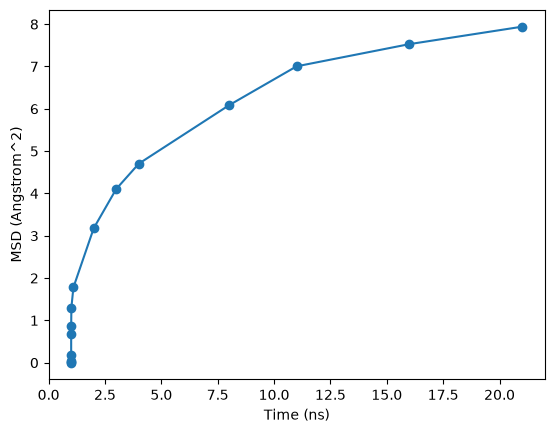

In [4]:
plt.plot(traj.timesteps/1e6, msd, 'o-')
plt.xlabel('Time (ns)')
plt.ylabel('MSD (Angstrom^2)')
plt.show()

## MSD of POSS cages

### Read the trajectory

In [5]:
traj = trajectory(path="../../data/BER/",
                  pattern="oaps_ber_325K.dump",
                  filter_type=False,
                  filter=False,
                  restore=False,
                  verbose=True
                  )

	File list contains 1 files
	Reading trajectory...
	Trajectory done!


### Calculate the MSD

In [6]:
# a list of the types in the system in the order of their atom type id
types = ['c',   # 1
         'c1',  # 2
         'c2',  # 3
         'c3',  # 4
         'cp',  # 5
         'h',   # 6
         'hc',  # 7
         'hn',  # 8
         'ho2', # 9
         'nn',  # 10
         'oc',  # 11
         'oh',  # 12
         'osi', # 13
         's1',  # 14
         'sio', # 15
        ]

is_poss_types = [13,15] # list of types comprising the POSS cage

# transfer that list of types to a list of masses
masses = types_to_masses(types, PCFF_MASSES)

type_array = traj.get_atoms().where( # list of every atom's type
    traj.get_atoms().type.isin(is_poss_types), drop=True # filter the dataset with only POSS cages
    ).type.isel(ts=0).values.astype(int)

msd = compute_msd_cm( # position of atoms unwrapped
    positions=traj.get_unwrapped().where(
        traj.get_atoms().type.isin(is_poss_types), drop=True # filter the dataset with only POSS cages
        ),
    types=type_array, # type for every atom
    masses=masses # mass for every type
)
msd

array([0.        , 0.02149304, 0.05746433, 0.16819137, 0.20325158,
       0.26622481, 0.33326558, 0.21788996, 0.19230005, 0.34819733])

### Plot the msd

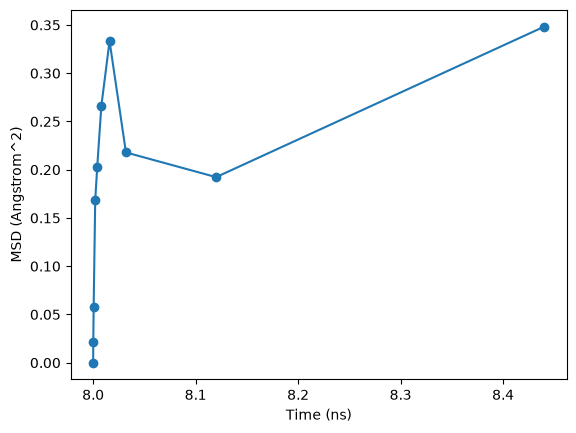

In [7]:
plt.plot(traj.timesteps/1e6, msd, 'o-')
plt.xlabel('Time (ns)')
plt.ylabel('MSD (Angstrom^2)')
plt.show()